# 14 · Errors and interpretation

[Guide](../README.md) | [Previous](13_Calibration_and_Thresholds.ipynb) | [Next](15_Final_Frozen_Solution.ipynb)

Inspect the chosen recipe, without changing its settings from these plots.

## Data: training, validation, competition test
`train.csv` contains known answers; `test.csv` does not.
Split `train.csv`: 16,000 rows for learning and comparisons; 4,000 validation rows for the final check.
Comparisons below stay inside the training part. `random_state` repeats the split;
`stratify` keeps similar goal/miss proportions. `X` means inputs; `y` means answers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

In [2]:
# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

Train: (20000, 20) Test: (6000, 19)


In [3]:
# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

In [4]:
# IDs identify rows; they do not describe how a penalty was taken.
id_columns = ["id", "kicker_id", "keeper_id", "match_id"]
X = training_data.drop(columns=id_columns + ["is_scored"])
y = training_data["is_scored"]

In [5]:
from sklearn.base import clone
from sklearn.compose import make_column_selector
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.feature_selection import SelectFromModel
from imblearn import FunctionSampler
from imblearn.pipeline import Pipeline
from catboost import CatBoostClassifier

## Continue from the earlier lessons

| Earlier decision | Choice used here |
|---|---|
| Missing | Drop incomplete training rows |
| Scaling | Robust scaling |
| Encoding | One-hot |
| Features | All candidate groups |
| Selection | Drop suspected decoys + L1 |
| Reduction | No PCA |
| Outliers | Add a flag |
| Balancing | Original class counts |
| Model | CatBoost |
| Tuning | Random search |
| Ensemble | Single model |
| Probabilities | Original probabilities |

Only the current choice changes. `clone` copies settings, not fitted knowledge; `step__setting` points to one pipeline setting.

**Incomplete training rows:** `any(axis=1)` finds a row with at least one blank; `~` keeps the opposite rows. Filter `y` too so answers stay aligned.

In [6]:
def remove_incomplete_rows(X, y):
    keep = ~X.isna().any(axis=1)
    return X.loc[keep], y[keep]

**Suspected decoys:** test removing jersey color and referee strictness, not every weak-looking input. The same columns are removed at prediction time.

In [7]:
def drop_suspected_decoys(data):
    return data.drop(columns=["jersey_color", "referee_strictness"], errors="ignore")

**Form and technique features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [8]:
def add_relative_features(data):
    data = data.copy()
    data["skill_gap"] = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["foot_advantage"] = data["strong_foot_usage"] - data["weak_foot_usage"]
    data["form_ratio"] = (data["player_last5_scored_percent"] + 1) / (data["goalkeeper_last5_saved_percent"] + 1)
    data["form_interaction"] = data["player_last5_scored_percent"] * data["goalkeeper_last5_saved_percent"] / 100
    data["player_form_squared"] = (data["player_last5_scored_percent"] / 100) ** 2
    data["keeper_form_squared"] = (data["goalkeeper_last5_saved_percent"] / 100) ** 2
    return data

**Match context features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [9]:
def add_pressure_features(data):
    data = data.copy()
    data["late_close_game"] = ((data["minute_taken"] >= 75) & (data["current_score_diff"].abs() <= 1)).astype(int)
    gap = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["skill_under_pressure"] = gap * data["late_close_game"]
    data["after_90_minutes"] = (data["minute_taken"] > 90).astype(int)
    data["trailing"] = (data["current_score_diff"] < 0).astype(int)
    data["tied_game"] = (data["current_score_diff"] == 0).astype(int)
    data["minute_score_interaction"] = data["minute_taken"] * data["current_score_diff"]
    data["crowd_support"] = (data["home_or_away"] == data["crowd_behind_goal"]).astype(int)
    data["late_final"] = ((data["minute_taken"] >= 75) & (data["match_type"] == "Final")).astype(int)
    return data

**Environment features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [10]:
def add_environment_features(data):
    data = data.copy()
    data["poor_pitch"] = (data["pitch_condition"] == "Poor").astype(int)
    data["poor_pitch_late"] = data["poor_pitch"] * (data["minute_taken"] >= 75)
    data["humidity_weak_foot"] = data["weather_humidity"] / 100 * data["weak_foot_usage"]
    data["humidity_squared"] = (data["weather_humidity"] / 100) ** 2
    data["temperature_squared"] = data["temperature"] ** 2
    data["log_capacity"] = np.log1p(data["stadium_capacity"])
    return data

In [11]:
def add_features(data):
    data = add_relative_features(data)
    data = add_pressure_features(data)
    return add_environment_features(data)

In [12]:
def suspicious_rows(data):
    # Screening rules, not proof: unusual time, cold weather, or very large venue.
    return ((data["minute_taken"] > 120) |
            (data["temperature"] < 0) |
            (data["stadium_capacity"] > 110000))

In [13]:
def add_outlier_flag(data):
    data = data.copy()
    data["unusual_kick"] = suspicious_rows(data).astype(int)
    return data

## Prepare each training split separately
Fill numbers with a training mean or median; fill categories with the most common value (**mode**).
Scaling puts numbers on similar scales. Encoding turns category names into numbers (Lesson 04).
No filling values, rankings, or sampling decisions are learned from validation rows.

In [14]:
numbers = Pipeline([("fill", SimpleImputer(strategy='median')), ("scale", RobustScaler())])
categories = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("numbers", numbers, make_column_selector(dtype_include="number")),
    ("categories", categories, make_column_selector(dtype_exclude="number")),
])

**Pipeline:** run steps in order. `passthrough` skips a step. `FunctionSampler` applies a row-changing function only during fitting; every prediction-time row is kept. Balancing also runs only during fitting.

In [15]:
pipeline = Pipeline([
    ("missing_rows", FunctionSampler(func=remove_incomplete_rows, validate=False)),
    ("outlier_values", FunctionTransformer(add_outlier_flag)),
    ("features", FunctionTransformer(add_features)),
    ("decoys", FunctionTransformer(drop_suspected_decoys)),
    ("prepare", preprocess),
    ("selection", SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000, random_state=42))),
    ("model", CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, loss_function='Logloss', random_seed=42, thread_count=2, verbose=False, allow_writing_files=False)),
])

In [16]:
selected_model = clone(pipeline)

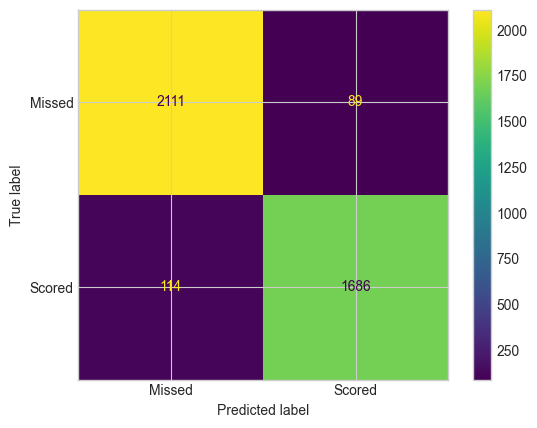

In [17]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay
X_fit, X_example, y_fit, y_example = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
selected_model.fit(X_fit, y_fit)
prediction = selected_model.predict(X_example)
probability = selected_model.predict_proba(X_example)[:, 1]
ConfusionMatrixDisplay.from_predictions(y_example, prediction, display_labels=["Missed", "Scored"])
plt.show()

**False positive:** predicted a goal but it was missed. **False negative:** predicted a miss but it was scored.
The matrix shows actual outcomes on rows and model predictions on columns.

In [18]:
example = X_example.copy()
example["actual"] = y_example
example["prediction"] = prediction
example["goal probability"] = probability
errors = example[example["actual"] != example["prediction"]]
example["error"] = example["actual"] != example["prediction"]
display(errors[["minute_taken", "player_last5_scored_percent", "goalkeeper_last5_saved_percent", "actual", "goal probability"]].head(8))

,minute_taken,player_last5_scored_percent,goalkeeper_last5_saved_percent,actual,goal probability
506,21.0,100,60,0,0.532
91,46.0,40,20,1,0.421
9919,86.0,100,100,1,0.260
10023,86.0,100,40,0,0.962
18,27.0,80,20,1,0.492
3434,4.0,80,80,1,0.152
8027,21.0,20,0,0,0.728
11596,13.0,60,20,0,0.569


## Four views of the mistakes
**False positives/negatives** separate the two error types. **High-confidence errors** are confident but wrong.
**Subgroups** check match types. **Probability buckets** group similar confidence levels.
Small groups give unreliable rates; these diagnostics do not authorize retuning on the separate validation set.

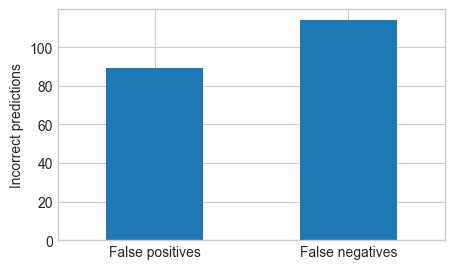

,actual,prediction,goal probability,confidence
10586,0,1,0.997,0.997
7355,0,1,0.992,0.992
6321,0,1,0.965,0.965
10023,0,1,0.962,0.962
7943,1,0,0.072,0.928


In [19]:
error_counts = pd.Series({
    "False positives": ((prediction == 1) & (y_example == 0)).sum(),
    "False negatives": ((prediction == 0) & (y_example == 1)).sum(),
})
error_counts.plot.bar(rot=0, figsize=(5, 3))
plt.ylabel("Incorrect predictions")
plt.show()
confidence = np.maximum(probability, 1 - probability)
example["confidence"] = confidence
display(example.loc[example["error"], ["actual", "prediction", "goal probability", "confidence"]].sort_values("confidence", ascending=False).head())

,kicks,error rate
match_type,,
Cup,1001,0.050
Final,530,0.043
Friendly,362,0.077
League,1829,0.048
Playoff,278,0.054


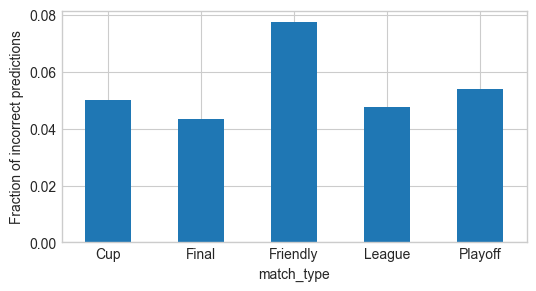

,kicks,predicted_rate,actual_rate
probability bucket,,,
"(-0.001, 0.2]",1955,0.023,0.008
"(0.2, 0.4]",190,0.289,0.274
"(0.4, 0.6]",162,0.504,0.574
"(0.6, 0.8]",175,0.712,0.783
"(0.8, 1.0]",1518,0.970,0.989


In [20]:
subgroup = example.groupby("match_type")["error"].agg(["size", "mean"])
subgroup.columns = ["kicks", "error rate"]
display(subgroup)
subgroup["error rate"].plot.bar(rot=0, figsize=(6, 3))
plt.ylabel("Fraction of incorrect predictions")
plt.show()
example["probability bucket"] = pd.cut(probability, bins=[0, 0.2, 0.4, 0.6, 0.8, 1], include_lowest=True)
buckets = example.groupby("probability bucket", observed=True).agg(kicks=("actual", "size"), predicted_rate=("goal probability", "mean"), actual_rate=("actual", "mean"))
display(buckets)

## Which inputs does the selected model rely on?
Permutation importance shuffles one input and measures lost F1 on these unseen example rows.

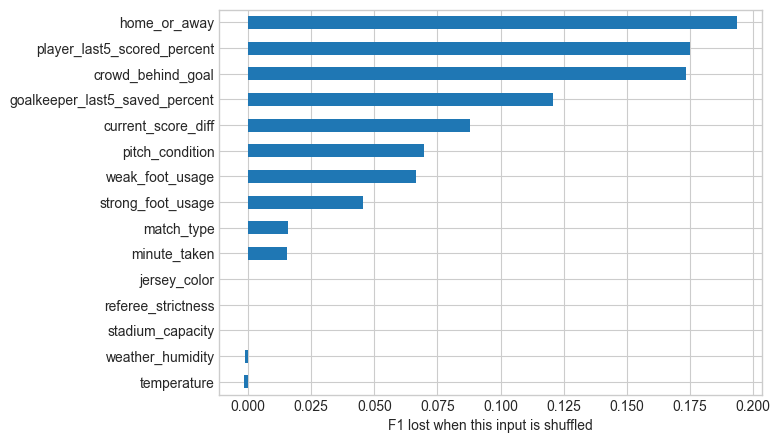

In [21]:
importance = permutation_importance(selected_model, X_example, y_example, scoring="f1", n_repeats=3, random_state=42)
ranking = pd.Series(importance.importances_mean, index=X.columns).sort_values()
ranking.plot.barh(figsize=(7, 5))
plt.xlabel("F1 lost when this input is shuffled")
plt.show()

Larger score loss means greater reliance, not causation. Correlated inputs can replace each other.
**Other options:** partial dependence varies one input; error clustering groups similar mistakes;
SHAP allocates predictions among inputs but adds explanation choices and computation.

These are training-part diagnostics. If a plot suggests a new method, evaluate that change separately.